# 3. Multilayered Dispersive Thin-Film Stack: Fabry–Pérot Interference

## Physical Motivation & Learning Objectives
Multilayer dielectric coatings manipulate reflection and transmission through **coherent multiple reflections**. In this tutorial:
1. We model an antireflection coating on crystalline silicon: $\mathrm{Air} / \mathrm{SiO}_2\,(100\,\mathrm{nm}) / \mathrm{Si}_3\mathrm{N}_4\,(70\,\mathrm{nm}) / \mathrm{Si\_c}$.
2. We analyze Fabry–Pérot interference fringes and layer-by-layer absorption resolution.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import concurrent.futures

from EMUstack.backend import materials, objects, plotting
from EMUstack.backend.stack import Stack


## Structure Definition

The stack consists of 4 layers ordered from bottom to top:
1. Substrate: Semi-infinite crystalline silicon (`materials.Si_c`)
2. Bottom thin film: $\mathrm{Si}_3\mathrm{N}_4$ ($d = 70$ nm, $n \approx 2.0$)
3. Top thin film: $\mathrm{SiO}_2$ ($d = 100$ nm, $n \approx 1.45$)
4. Superstrate: Semi-infinite air (`materials.Air`)


In [2]:
wavelengths = np.linspace(350, 1100, 20)
period = 500.0  # nm

light_list = [objects.Light(wl, max_order_PWs=1, theta=0.0, phi=0.0) for wl in wavelengths]

superstrate = objects.ThinFilm(period, height_nm='semi_inf', material=materials.Air, loss=False)
sio2_layer  = objects.ThinFilm(period, height_nm=100.0, material=materials.SiO2, loss=True)
si3n4_layer = objects.ThinFilm(period, height_nm=70.0, material=materials.Si3N4, loss=True)
substrate   = objects.ThinFilm(period, height_nm='semi_inf', material=materials.Si_c, loss=True)

def simulate_stack(light):
    sim_sup = superstrate.calc_modes(light)
    sim_sio2 = sio2_layer.calc_modes(light)
    sim_si3n4 = si3n4_layer.calc_modes(light)
    sim_sub = substrate.calc_modes(light)
    
    # Bottom to top ordering
    stk = Stack((sim_sub, sim_si3n4, sim_sio2, sim_sup))
    stk.calc_scat(pol='TE')
    return stk

with concurrent.futures.ThreadPoolExecutor() as executor:
    stacks_list = list(executor.map(simulate_stack, light_list))


 substrate therefore cannot calculate energy fluxes here.
 superstrate therefore CANNOT CALCULATE ENERGY FLUXES ANYWHERE.
 substrate therefore cannot calculate energy fluxes here.
 superstrate therefore CANNOT CALCULATE ENERGY FLUXES ANYWHERE.
 substrate therefore cannot calculate energy fluxes here.
 superstrate therefore CANNOT CALCULATE ENERGY FLUXES ANYWHERE.
 substrate therefore cannot calculate energy fluxes here.
 superstrate therefore CANNOT CALCULATE ENERGY FLUXES ANYWHERE.
 substrate therefore cannot calculate energy fluxes here.
 superstrate therefore CANNOT CALCULATE ENERGY FLUXES ANYWHERE.
 substrate therefore cannot calculate energy fluxes here.
 superstrate therefore CANNOT CALCULATE ENERGY FLUXES ANYWHERE.
 substrate therefore cannot calculate energy fluxes here.
 superstrate therefore CANNOT CALCULATE ENERGY FLUXES ANYWHERE.
 substrate therefore cannot calculate energy fluxes here.
 superstrate therefore CANNOT CALCULATE ENERGY FLUXES ANYWHERE.
 substrate therefore can

## Layer-by-Layer Transmission, Reflection, and Absorption Spectra


<ipython-input-1-667545d58221>:2: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


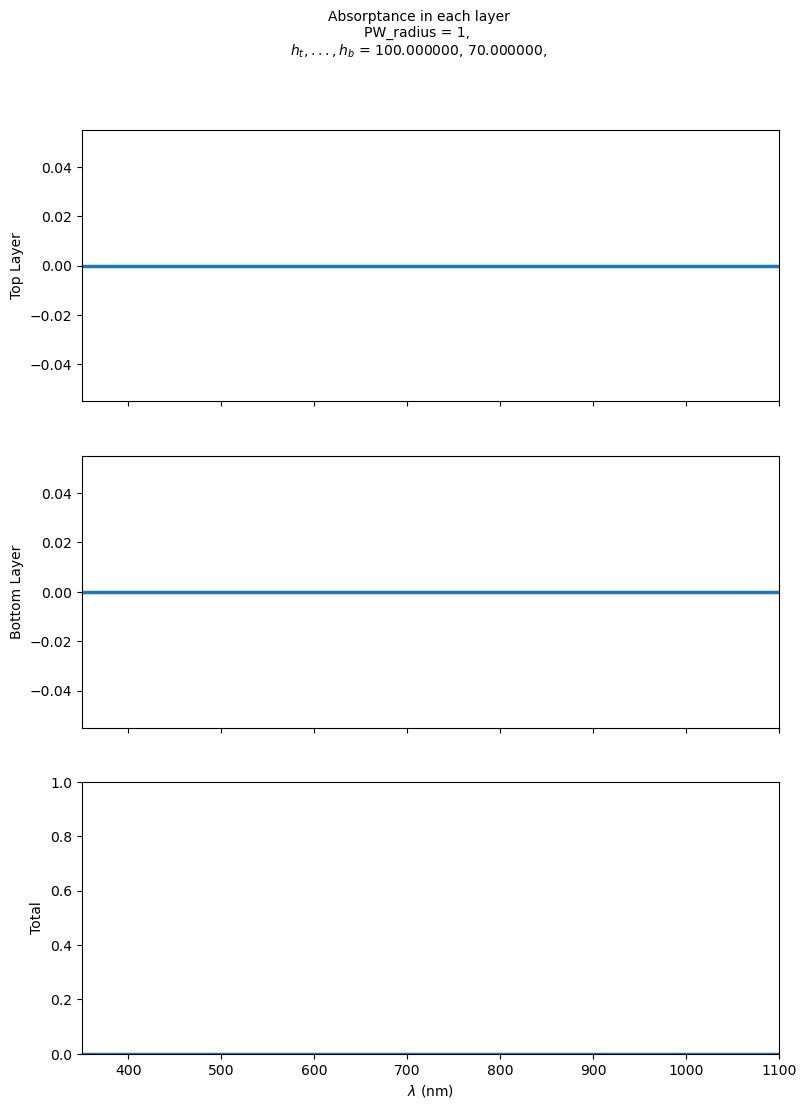

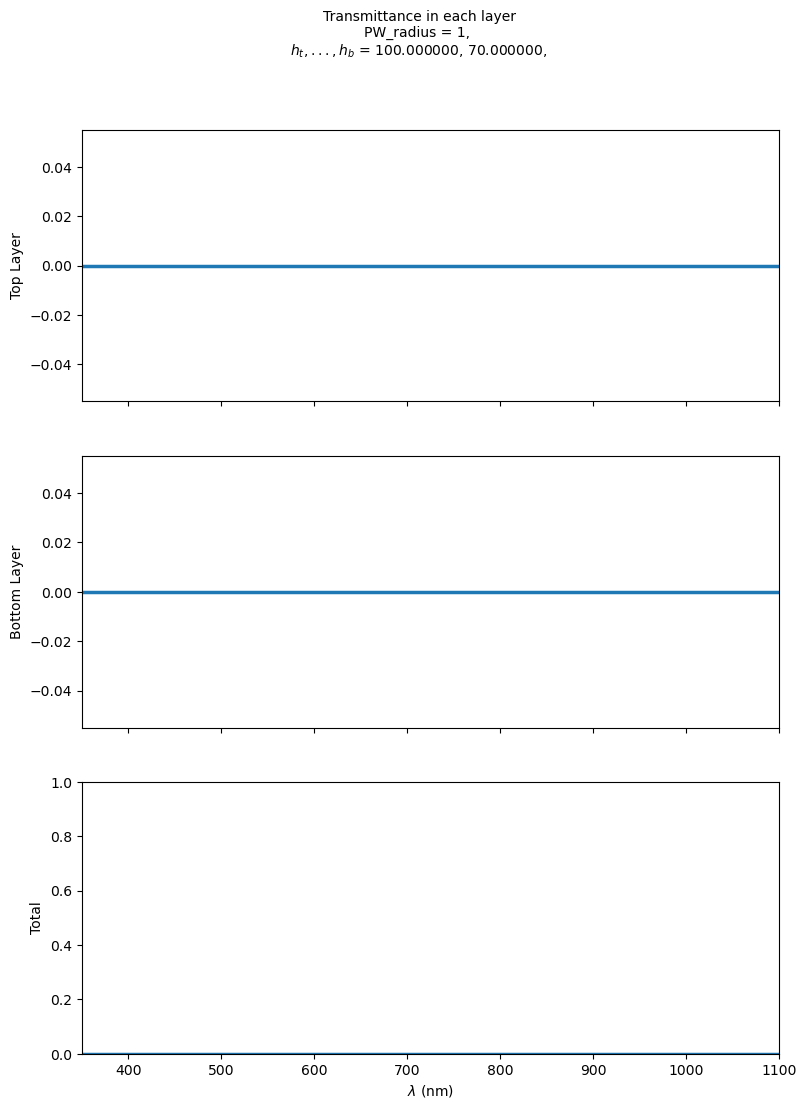

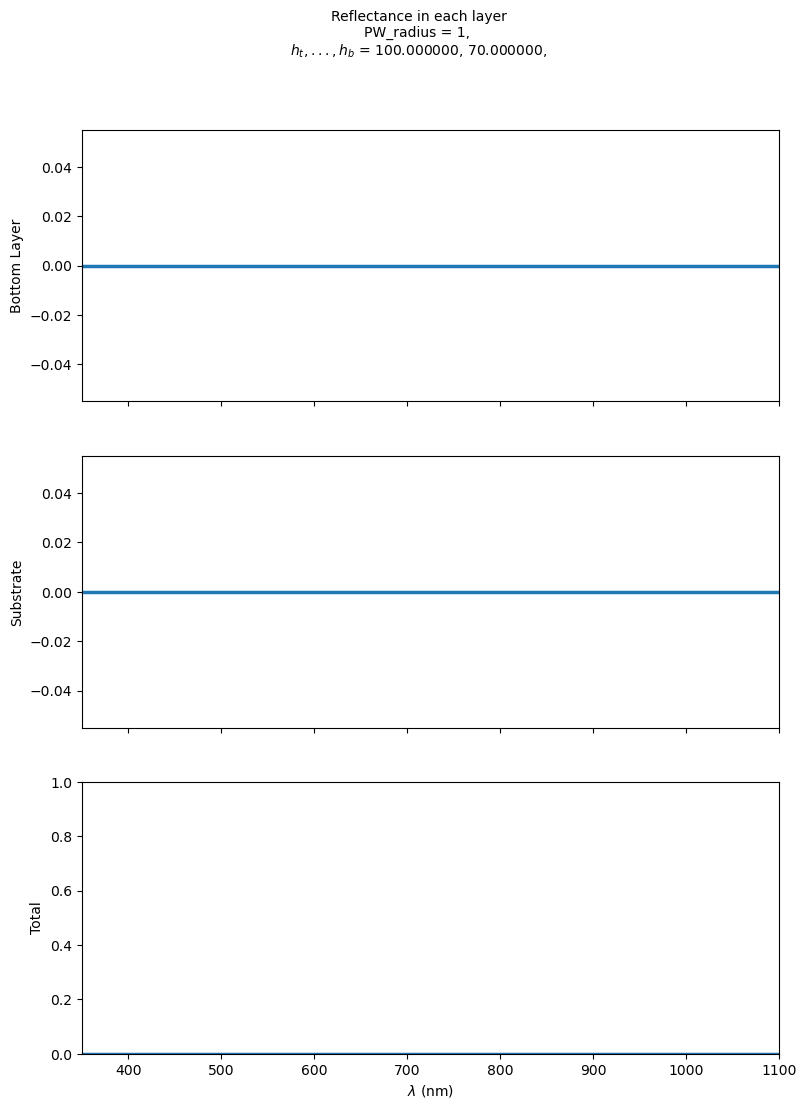

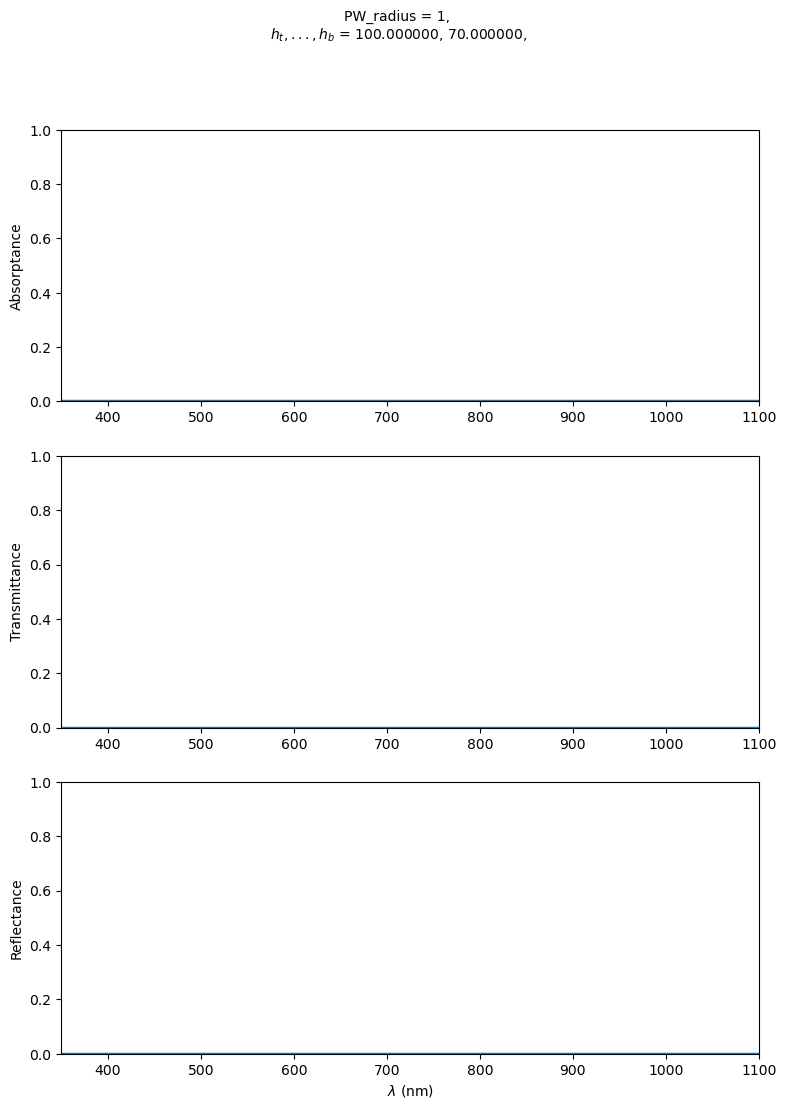

In [3]:
fig_tra = plotting.t_r_a_plots(stacks_list, plot_layers=True, save_pdf=False, save_txt=False)
plt.show()


## Physical Interpretation
- The double-layer coating suppresses reflection across the visible spectrum ($R < 10\%$ between 500 and 800 nm), demonstrating the antireflection principle.
- Almost all absorption occurs in the silicon substrate, while the dielectric coating layers ($\mathrm{SiO}_2$ and $\mathrm{Si}_3\mathrm{N}_4$) remain virtually lossless.
